# 📡 O-RAN dApp Geliştirme, Test ve Performans Analizi Çalışma Kitabı

Bu Jupyter Notebook; **wineslab** O-RAN **E3 Arayüzü (`libe3` / `libe3py`)** ve **`dApp-library`** kullanılarak gerçek zamanlı (alt-milisaniye / TTI seviyesinde) **dApp geliştirme, çalıştırma, mevcut kullanım senaryolarını (use-case) test etme ve sonuçları görsel olarak analiz etme** amacıyla hazırlanmıştır.

---

## 🏗️ Mimari Yapı: `libe3` (E3AP) + `dApp-library` (E3SM)

O-RAN dApp mimarisi görev ayrımı prensibiyle iki katmandan oluşur:
1. **C++ `libe3` (`libe3py` SWIG Köprüsü):** **E3AP (E3 Application Protocol)** katmanını yönetir. ZMQ veya POSIX soketleri üzerinden IPC/TCP/SCTP bağlantısını, `Setup` el sıkışmasını, `Subscription` yönetimini, `Indication`/`Control` çerçevelemesini ve kilit-serbest (lock-free) halka tamponlarını (`DAppSession.poll_events`) yürütür.
2. **Python `dApp-library`:** **E3SM (E3 Service Model)** katmanını yönetir. Servis modeli yüklerini (ASN.1 APER, JSON veya Protobuf) çözer, I/Q örneklerini paylaşımlı bellekten (`POSIX shm`) veya mesaj içerisinden okur ve spektrum algılama / PRB karalisteleme (PRB Barring) algoritmalarını çalıştırır.

### 📋 İçindekiler
1. **Bölüm 1:** Ortam Doğrulama, Konfigürasyon (`e3_config.json`) ve Radyo Profilleri (`RU_PROFILES`) Analizi
2. **Bölüm 2:** Use Case 1 — `libe3` Native C++ Agent & Python `SimpleDApp` (ASN.1 / JSON / Protobuf) El Sıkışma ve Codec Kıyaslaması
3. **Bölüm 3:** Use Case 2 — DU Simülatörü (`mock_du_e3_agent.py`) & İlk dApp (`my_first_dapp.py`) Canlı Test ve Spektrum Analizi
4. **Bölüm 4:** Use Case 3 — `SpectrumSharingDApp` Dedektörleri (`Static`, `Adaptive`, `BaselinePolicy`) ve **Özel (Custom) dApp Politikası Geliştirme**
5. **Bölüm 5:** Otomatik Test Koşumu (`pytest` & `libe3` Smoke Testleri) ve Sonuç Özeti

## 🛠️ Bölüm 0: Ön Gereksinimler ve Otomatik Ortam Yapılandırması (Setup of Requirements)

Bu hücre, çalışma ortamını (`.venv`, Python çekirdeği, C++ SWIG kütüphaneleri) otomatik olarak analiz eder:
- Aktif Python çalışma ortamını ve işletim sistemini denetler.
- Çalışma alanındaki sanal ortam dizinini (`.venv/.../site-packages`) ve `.pth` bağlantılarını `site.addsitedir` ile `sys.path`'e bağlar.
- Gerekli her bir paketi (`libe3py`, `pyzmq`, `numpy`, `matplotlib`, `asn1tools`, `protobuf`, `sigmf`, `jsonschema`, `dapp-library`) tek tek kontrol eder;
  - **Zaten kuruluysa:** Yeniden kurmaz, sürümünü raporlar.
  - **Eksikse:** `pip` üzerinden otomatik olarak kurar veya derleme adımını tetikler.
- Böylece notebook hangi çekirdekle başlatılırsa başlatılsın (ister sistem Python, ister `.venv`) `ModuleNotFoundError` yaşanmaz.

In [1]:
# ==============================================================================
# 0. SETUP OF REQUIREMENTS & DYNAMIC ENVIRONMENT BOOTSTRAP
# ==============================================================================
import sys
import os
import platform
import site
import subprocess
import importlib.util

print("🔍 [1/4] Çalışma Ortamı ve Çekirdek Denetleniyor...")
is_windows = platform.system() == "Windows"
print(f"  • İşletim Sistemi : {platform.system()} ({platform.release()})")
print(f"  • Python Binary   : {sys.executable}")
print(f"  • Python Sürümü   : {sys.version.split()[0]}")

if is_windows:
    print("\n⚠️  UYARI: Windows yerel Python ortamı algılandı!")
    print("   libe3 ve dApp-library C++ Linux paylaşımlı kütüphaneleri (_libe3py.so) ile derlenmiştir.")
    print("   Eğer bu notebook'u VS Code veya Jupyter üzerinden çalıştırıyorsanız:")
    print("   👉 Sağ üstteki Kernel menüsünden 'WSL: Python 3 (.venv - O-RAN dApp)' veya 'WSL: Ubuntu' kernelini seçin.\n")

# 1. Çalışma alanı kök dizinini ve .venv site-packages yolunu belirle
WS_ROOT = os.path.abspath(os.getcwd())
if not os.path.exists(os.path.join(WS_ROOT, "e3_config.json")) and os.path.exists(os.path.join(os.path.dirname(WS_ROOT), "e3_config.json")):
    WS_ROOT = os.path.dirname(WS_ROOT)

# Olası .venv site-packages ve dApp-library dizinlerini ekle
candidate_paths = [
    os.path.join(WS_ROOT, ".venv", "lib", f"python{sys.version_info.major}.{sys.version_info.minor}", "site-packages"),
    os.path.join(WS_ROOT, ".venv", "lib", "python3.8", "site-packages"),
    os.path.join(WS_ROOT, "dApp-library", "src"),
    os.path.join(WS_ROOT, "libe3", "swig"),
]

for p in candidate_paths:
    if os.path.exists(p):
        # site.addsitedir hem dizini ekler hem de .pth (editable dapps vb.) dosyalarını yürütür
        site.addsitedir(p)
        if p not in sys.path:
            sys.path.insert(0, p)

print("\n📦 [2/4] Python Bağımlılıkları Kontrol Ediliyor (Kurulu olanlar korunur, eksikler tamamlanır)...")
REQUIRED_PACKAGES = [
    ("numpy", "numpy"),
    ("matplotlib", "matplotlib"),
    ("zmq", "pyzmq"),
    ("asn1tools", "asn1tools"),
    ("google.protobuf", "protobuf"),
    ("sigmf", "sigmf"),
    ("jsonschema", "jsonschema"),
    ("pytest", "pytest"),
]

missing_pip = []
for import_name, pkg_name in REQUIRED_PACKAGES:
    try:
        mod = importlib.import_module(import_name)
        ver = getattr(mod, "__version__", "mevcut")
        print(f"  ✅ [MEVCUT] {pkg_name:<16} (v{ver})")
    except ImportError:
        print(f"  ⚠️  [EKSİK]  {pkg_name:<16} -> Yüklenecek")
        missing_pip.append(pkg_name)

if missing_pip:
    print(f"\n⬇️ Eksik paketler kuruluyor: {missing_pip}...")
    subprocess.check_call([sys.executable, "-m", "pip", "install"] + missing_pip)
    print("  ✅ Eksik paketler başarıyla yüklendi.")

print("\n⚙️  [3/4] C++ SWIG Köprüsü (libe3py) Doğrulanıyor...")
try:
    import libe3py
    print(f"  ✅ [MEVCUT] libe3py (SWIG C++ Köprüsü, v{getattr(libe3py, '__version__', '0.4.0')})")
except ImportError:
    print("  ⚠️  libe3py modülü bulunamadı, derleme kontrol ediliyor...")
    swig_so = os.path.join(WS_ROOT, "libe3", "swig", "_libe3py.so")
    if not os.path.exists(swig_so):
        print("  🔨 build_swig.sh çalıştırılıyor...")
        subprocess.check_call(["bash", os.path.join(WS_ROOT, "build_swig.sh")])
    site.addsitedir(os.path.join(WS_ROOT, "libe3", "swig"))
    import libe3py
    print(f"  ✅ [MEVCUT] libe3py derlendi ve yüklendi (v{getattr(libe3py, '__version__', '0.4.0')})")

print("\n🛰️  [4/4] dApp-library Modülleri Doğrulanıyor...")
dapp_pkgs = ["dapp", "e3interface", "spectrum", "simple"]
for dp in dapp_pkgs:
    try:
        importlib.import_module(dp)
        print(f"  ✅ [MEVCUT] {dp} modülü")
    except ImportError:
        print(f"  ⚠️  {dp} eksik, dApp-library kaynak dizini sys.path'e ekleniyor...")
        dapp_src = os.path.join(WS_ROOT, "dApp-library", "src")
        site.addsitedir(dapp_src)
        importlib.import_module(dp)
        print(f"  ✅ [MEVCUT] {dp} modülü (sys.path üzerinden yüklendi)")

print("\n" + "="*65)
print("🚀 TÜM GEREKSİNİMLER TAMAMLANDI! Hücreleri sırayla çalıştırabilirsiniz.")
print("="*65)


🔍 [1/4] Çalışma Ortamı ve Çekirdek Denetleniyor...
  • İşletim Sistemi : Linux (6.6.87.2-microsoft-standard-WSL2)
  • Python Binary   : /mnt/c/Users/cem.kaya/OneDrive - Odine Solutions/Documents/CustomerProjects/oran-dapp-workspace/.venv/bin/python3
  • Python Sürümü   : 3.8.10

📦 [2/4] Python Bağımlılıkları Kontrol Ediliyor (Kurulu olanlar korunur, eksikler tamamlanır)...


  ✅ [MEVCUT] numpy            (v1.24.4)


  ✅ [MEVCUT] matplotlib       (v3.7.5)
  ✅ [MEVCUT] pyzmq            (v27.1.0)


  ✅ [MEVCUT] asn1tools        (v0.169.0)
  ✅ [MEVCUT] protobuf         (v5.29.6)


  ✅ [MEVCUT] sigmf            (v1.11.1)
  ✅ [MEVCUT] jsonschema       (v4.23.0)


/tmp/ipykernel_29569/297021685.py:59: DeprecationWarning: Accessing jsonschema.__version__ is deprecated and will be removed in a future release. Use importlib.metadata directly to query for jsonschema's version.
  ver = getattr(mod, "__version__", "mevcut")


  ✅ [MEVCUT] pytest           (v8.3.5)

⚙️  [3/4] C++ SWIG Köprüsü (libe3py) Doğrulanıyor...
  ✅ [MEVCUT] libe3py (SWIG C++ Köprüsü, v0.4.0)

🛰️  [4/4] dApp-library Modülleri Doğrulanıyor...
  ✅ [MEVCUT] dapp modülü


  ✅ [MEVCUT] e3interface modülü
  ✅ [MEVCUT] spectrum modülü
  ✅ [MEVCUT] simple modülü

🚀 TÜM GEREKSİNİMLER TAMAMLANDI! Hücreleri sırayla çalıştırabilirsiniz.


---
## 1️⃣ Bölüm 1: Ortam Doğrulama ve Radyo Konfigürasyonu Analizi

İlk adımda sanal ortamımızdaki (`.venv`) C++ SWIG köprüsü (`libe3py`), `dApp-library` alt paketleri (`dapp`, `e3interface`, `spectrum`, `simple`) ve `e3_config.json` yapılandırma dosyamızı doğruluyoruz.

In [2]:
# Otomatik ortam ve path güvenliği (herhangi bir hücre doğrudan çalıştırıldığında)
import os, sys, site
for p in [os.path.abspath('.venv/lib/python3.8/site-packages'), os.path.abspath('dApp-library/src'), os.path.abspath('libe3/swig')]:
    if os.path.exists(p):
        site.addsitedir(p)
        if p not in sys.path: sys.path.insert(0, p)

import os
import sys
import json
import time
import subprocess
import numpy as np
import matplotlib.pyplot as plt

# Grafik ayarları
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# dApp ve libe3 modüllerini içe aktar
import libe3py
import zmq
import asn1tools
import google.protobuf
import sigmf
import jsonschema

from dapp.dapp import DApp
from e3interface.e3_interface import E3Interface
from e3interface.libe3_agent import Libe3Agent, LIBE3_MIN_VERSION
from simple.simple_dapp import SimpleDApp
from spectrum.spectrum_dapp import SpectrumSharingDApp, compute_fft_size
from spectrum.ru_profiles import RU_PROFILES, resolve_ru_settings
from spectrum.threshold_detector import StaticThresholdDetector, AdaptiveThresholdDetector
from spectrum.policy import Policy, BaselinePolicy, Observation, PolicyDetector

print("✅ Bütün O-RAN dApp modülleri başarıyla yüklendi!\n")
print(f"{'Bileşen':<28} | {'Versiyon / Durum':<25}")
print("-" * 58)
print(f"{'Python Interpreter':<28} | {sys.version.split()[0]}")
print(f"{'libe3py (SWIG C++ Bridge)':<28} | v{getattr(libe3py, '__version__', 'unknown')} (Min: v{LIBE3_MIN_VERSION})")
print(f"{'PyZMQ':<28} | v{zmq.__version__} (libzmq v{zmq.zmq_version()})")
print(f"{'NumPy':<28} | v{np.__version__}")
print(f"{'ASN.1 Tools (APER Codec)':<28} | v{asn1tools.__version__}")
print(f"{'Google Protobuf':<28} | v{google.protobuf.__version__}")
print(f"{'SigMF (I/Q Kayıt Formatı)':<28} | v{sigmf.__version__}")

✅ Bütün O-RAN dApp modülleri başarıyla yüklendi!

Bileşen                      | Versiyon / Durum         
----------------------------------------------------------
Python Interpreter           | 3.8.10
libe3py (SWIG C++ Bridge)    | v0.4.0 (Min: v0.2.0)
PyZMQ                        | v27.1.0 (libzmq v4.3.5)
NumPy                        | v1.24.4
ASN.1 Tools (APER Codec)     | v0.169.0
Google Protobuf              | v5.29.6
SigMF (I/Q Kayıt Formatı)    | v1.11.1


In [3]:
# e3_config.json dosyasını oku ve radyo parametrelerini analiz et
with open("e3_config.json", "r") as f:
    e3_cfg = json.load(f)["E3Configuration"]

radio = e3_cfg["radioConfig"]
num_prbs = radio["numPrbs"]
scs_khz = radio["subcarrierSpacingKhz"]
center_freq_ghz = radio["centerFreqHz"] / 1e9
total_subcarriers = num_prbs * 12
occupied_bw_mhz = (total_subcarriers * scs_khz) / 1e3
fft_size_std = compute_fft_size(num_prbs, e_sampling=False)
fft_size_3_4 = compute_fft_size(num_prbs, e_sampling=True)

print("📌 Aktif E3 Konfigürasyonu (e3_config.json):")
print(f"  • RAN Node ID          : {e3_cfg['ranNodeId']}")
print(f"  • Bağlantı / Taşıma    : {e3_cfg['link'].upper()} / {e3_cfg['transport'].upper()} ({e3_cfg['encoding'].upper()})")
print(f"  • IPC Soket Dizini     : {e3_cfg['ipcSocketDir']}")
print(f"  • Telemetri Periyodu   : {e3_cfg['telemetryPeriodUs']} µs ({e3_cfg['telemetryPeriodUs']/1000:.1f} ms)")
print(f"  • Radyo Profili (RU)   : {radio['ruProfile']}")
print(f"  • PRB Sayısı           : {num_prbs} PRB ({total_subcarriers} Alt Taşıyıcı)")
print(f"  • Alt Taşıyıcı Aralığı : {scs_khz} kHz (Numeroloji µ=1)")
print(f"  • Merkez Frekansı      : {center_freq_ghz:.4f} GHz (n78 5G NR Bandı)")
print(f"  • İşgal Edilen BW      : {occupied_bw_mhz:.2f} MHz")
print(f"  • FFT Boyutu           : {fft_size_std} (Standart) / {fft_size_3_4} (USRP 3/4 Örnekleme)")
print(f"  • FP16 Ölçekleme Beta  : {radio['fp16Beta']} (1/{int(1/radio['fp16Beta'])})")

print("\n📻 dApp-library İçerisindeki Hazır Radyo Birimi (RU) Profilleri:")
print(f"{'Profil Adı':<14} | {'PRB':<5} | {'SCS (kHz)':<9} | {'Merkez Frek (GHz)':<18} | {'Eşik (dB)':<10} | {'FP16 Beta':<12}")
print("-" * 80)
for ru_name in RU_PROFILES:
    s = resolve_ru_settings(ru_name)
    print(f"{ru_name:<14} | {s['num_prbs']:<5} | {s['num_subcarrier_spacing']:<9} | "
          f"{s['center_freq']/1e9:<18.4f} | {s['noise_floor_threshold']:<10} | {s['fp16_beta']:<12.6f}")

📌 Aktif E3 Konfigürasyonu (e3_config.json):
  • RAN Node ID          : gnb-du-local-01
  • Bağlantı / Taşıma    : ZMQ / IPC (JSON)
  • IPC Soket Dizini     : /tmp/e3_sockets
  • Telemetri Periyodu   : 1000 µs (1.0 ms)
  • Radyo Profili (RU)   : rfsim
  • PRB Sayısı           : 51 PRB (612 Alt Taşıyıcı)
  • Alt Taşıyıcı Aralığı : 30 kHz (Numeroloji µ=1)
  • Merkez Frekansı      : 3.6192 GHz (n78 5G NR Bandı)
  • İşgal Edilen BW      : 18.36 MHz
  • FFT Boyutu           : 612 (Standart) / 612 (USRP 3/4 Örnekleme)
  • FP16 Ölçekleme Beta  : 0.00048828125 (1/2048)

📻 dApp-library İçerisindeki Hazır Radyo Birimi (RU) Profilleri:
Profil Adı     | PRB   | SCS (kHz) | Merkez Frek (GHz)  | Eşik (dB)  | FP16 Beta   
--------------------------------------------------------------------------------
usrp           | 106   | 30        | 3.6192             | 20         | 0.007812    
x410           | 106   | 30        | 3.6192             | 20         | 0.007812    
x310-3p58      | 106   | 30        

---
## 2️⃣ Bölüm 2: Use Case 1 — `libe3` C++ Agent ile Python `SimpleDApp` E3AP El Sıkışması ve Codec Analizi

Bu senaryoda:
1. **Gerçek E3AP/E3SM Testi:** C++ ile derlenmiş `./libe3/build/example_simple_agent` arka planda başlatılır ve Python'daki `SimpleDApp` (`dApp-library/src/simple/simple_dapp.py`) ya da `libe3py.DAppSession` doğrudan bağlanarak **ASN.1 APER** üzerinden:
   - `E3 Setup Request / Response`
   - `E3 Subscription Request / Response`
   - `E3 Indication` (telemetri akışı)
   - `E3 DAppControlAction` ve `MessageAck`
   adımlarını uçtan uca tamamlar.
2. **Servis Modeli Codec Kıyaslaması (ASN.1 APER vs JSON vs Protobuf):** Aynı `Simple-Indication` ve `Simple-Control` mesajlarının tel üzerindeki boyutları (byte) ve kodlama/çözme hızları (µs) ölçülerek karşılaştırılır.

In [4]:
# 1. C++ example_simple_agent ile Python libe3py DAppSession (ASN.1 APER) Canlı El Sıkışma ve Telemetri Testi
socket_dir = "/tmp/dapps"
os.makedirs(socket_dir, exist_ok=True)
for f in os.listdir(socket_dir):
    try:
        os.remove(os.path.join(socket_dir, f))
    except OSError:
        pass

# C++ Agent'ı 25 ms periyot ile arka planda başlat
agent_proc = subprocess.Popen(
    ["./libe3/build/example_simple_agent", "--socket-dir", socket_dir, "--period-us", "25000", "--encoding", "asn1"],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL,
)
time.sleep(0.6)

# ASN.1 derleyicisini hazırla
from simple.simple_dapp import _locate_simple_asn
asn_path = _locate_simple_asn()
simple_asn_codec = asn1tools.compile_files(asn_path, codec="per")

# libe3py üzerinden DAppSession yapılandır
cfg = libe3py.E3Config()
cfg.role = libe3py.E3Role_DAPP
cfg.link_layer = libe3py.E3LinkLayer_ZMQ
cfg.transport_layer = libe3py.E3TransportLayer_IPC
cfg.encoding = libe3py.EncodingFormat_ASN1
cfg.dapp_name = "NotebookSimpleDApp"
cfg.version = "1.0.0"
cfg.vendor = "OdineLab"
cfg.ipc_socket_dir = socket_dir

session = libe3py.DAppSession(cfg)
rc_start = session.start()
rc_setup = session.wait_for_setup(5000)

print(f"🔗 [E3AP Setup] start={rc_start}, wait_for_setup={rc_setup}, Atanan dApp ID={session.dapp_id()}")
print(f"📡 [RAN Bilgisi] RAN ID='{session.ran_identifier()}', RAN Fonksiyon Sayısı={session.setup_ran_function_count()}")

for i in range(session.setup_ran_function_count()):
    rfid = session.setup_ran_function_id(i)
    rfd_bytes = session.setup_ran_function_data(i)
    rfd_decoded = simple_asn_codec.decode("Simple-RanFunctionData", rfd_bytes) if rfd_bytes else {}
    print(f"   • RAN Function #{rfid}: Telemetry IDs={list(session.setup_ran_function_telemetry(i))}, "
          f"Control IDs={list(session.setup_ran_function_control(i))}, Data={rfd_decoded}")

# RAN Function 1'e abone ol
req_id = session.subscribe(1, [1], [1], -1, -1)
print(f"📝 [E3AP Subscribe] İstek gönderildi (request_id={req_id})")

indications_log = []
acks_received = 0
controls_sent = 0

t0 = time.perf_counter()
while time.perf_counter() - t0 < 1.2:
    events = session.poll_events(64, 50)
    for ev in events:
        if ev.kind == libe3py.E3_EVENT_SUBSCRIPTION_RESPONSE:
            print(f"✅ [E3AP SubResponse] Abonelik onaylandı! sub_id={ev.subscription_id}, rc={ev.response_code}")
        elif ev.kind == libe3py.E3_EVENT_INDICATION:
            payload = ev.get_payload()
            decoded = simple_asn_codec.decode("Simple-Indication", payload)
            rx_ns = time.time_ns()
            indications_log.append({
                "seq": decoded["data1"],
                "tx_ts_ms": decoded["timestamp"],
                "wire_bytes": len(payload),
                "rx_time_s": time.perf_counter() - t0
            })
            # Her 5 indication'da bir Simple-Control gönder
            if decoded["data1"] % 5 == 0:
                ctrl_bytes = simple_asn_codec.encode("Simple-Control", {"samplingThreshold": int(decoded["data1"] % 101)})
                session.send_control(1, 1, ctrl_bytes, int(decoded["data1"]))
                controls_sent += 1
        elif ev.kind == libe3py.E3_EVENT_MESSAGE_ACK:
            acks_received += 1

session.release()
session.stop()
agent_proc.terminate()
try:
    agent_proc.wait(timeout=2)
except subprocess.TimeoutExpired:
    agent_proc.kill()

print(f"\n📊 [Test Özeti] Alınan Indication: {len(indications_log)} | Gönderilen Control: {controls_sent} | Alınan ACK: {acks_received} | Drop: {session.dropped_events()}")
if indications_log:
    print(f"   İlk 3 Indication: {indications_log[:3]}")

[2026-11-11 17:05:19.142] [INFO ] [E3Agent] E3Agent created (version 0.4.0)
[2026-11-11 17:05:19.146] [INFO ] [E3Agent] Initializing E3Agent


🔗 [E3AP Setup] start=0, wait_for_setup=0, Atanan dApp ID=1
📡 [RAN Bilgisi] RAN ID='example-ran-001', RAN Fonksiyon Sayısı=1
   • RAN Function #1: Telemetry IDs=[1], Control IDs=[1], Data={'name': 'SIMPLE'}


📝 [E3AP Subscribe] İstek gönderildi (request_id=2)
✅ [E3AP SubResponse] Abonelik onaylandı! sub_id=1, rc=0



📊 [Test Özeti] Alınan Indication: 40 | Gönderilen Control: 8 | Alınan ACK: 8 | Drop: 0
   İlk 3 Indication: [{'seq': 0, 'tx_ts_ms': 1257074056, 'wire_bytes': 7, 'rx_time_s': 0.23555899599887198}, {'seq': 1, 'tx_ts_ms': 1257074081, 'wire_bytes': 7, 'rx_time_s': 0.2604332829996565}, {'seq': 2, 'tx_ts_ms': 1257074106, 'wire_bytes': 7, 'rx_time_s': 0.2853734029995394}]


Codec Formatı   | Indication Boyutu (Byte) | Control Boyutu (Byte)  | Encode+Decode Süresi (µs)
--------------------------------------------------------------------------------------------
ASN.1 APER      | 7                        | 1                      | 34.54                    
Protobuf        | 7                        | 2                      | 1.74                     
JSON            | 37                       | 25                     | 6.96                     


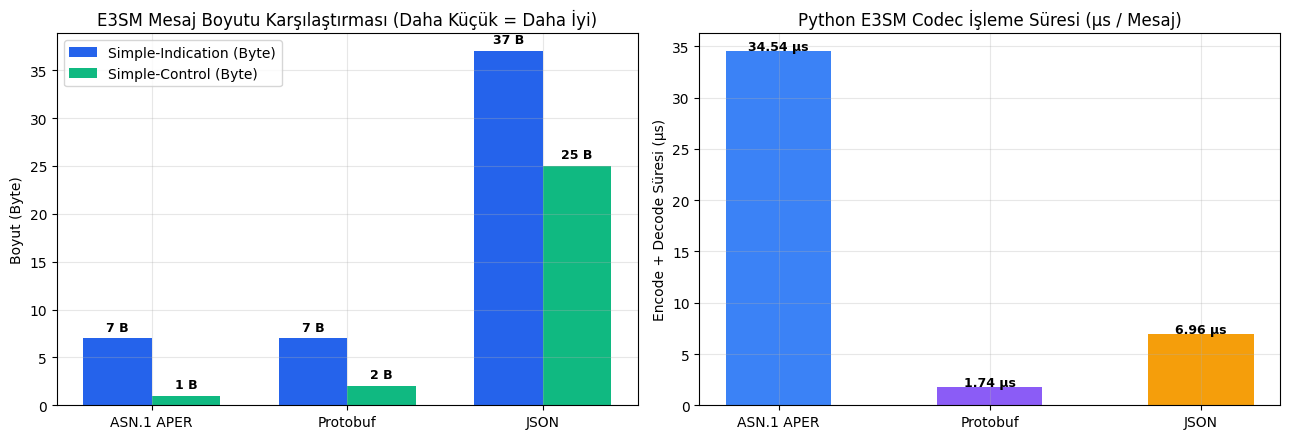

In [5]:
# 2. E3SM Codec Karşılaştırması: ASN.1 APER vs JSON vs Protobuf
from simple.defs import e3sm_simple_pb2
from google.protobuf import json_format

sample_ind_dict = {"data1": 42, "timestamp": 123456789}
sample_ctrl_dict = {"samplingThreshold": 75}

N_ITER = 2000
results = {}

# --- ASN.1 APER ---
asn_ind_bytes = simple_asn_codec.encode("Simple-Indication", sample_ind_dict)
asn_ctrl_bytes = simple_asn_codec.encode("Simple-Control", sample_ctrl_dict)
t_s = time.perf_counter()
for _ in range(N_ITER):
    b = simple_asn_codec.encode("Simple-Indication", sample_ind_dict)
    _ = simple_asn_codec.decode("Simple-Indication", b)
t_asn_us = ((time.perf_counter() - t_s) / N_ITER) * 1e6
results["ASN.1 APER"] = {"ind_bytes": len(asn_ind_bytes), "ctrl_bytes": len(asn_ctrl_bytes), "roundtrip_us": t_asn_us}

# --- Protobuf ---
pb_ind = e3sm_simple_pb2.SimpleIndication(data1=42, timestamp=123456789)
pb_ctrl = e3sm_simple_pb2.SimpleControl(sampling_threshold=75)
pb_ind_bytes = pb_ind.SerializeToString()
pb_ctrl_bytes = pb_ctrl.SerializeToString()
t_s = time.perf_counter()
for _ in range(N_ITER):
    msg = e3sm_simple_pb2.SimpleIndication(data1=42, timestamp=123456789)
    b = msg.SerializeToString()
    msg2 = e3sm_simple_pb2.SimpleIndication()
    msg2.ParseFromString(b)
t_pb_us = ((time.perf_counter() - t_s) / N_ITER) * 1e6
results["Protobuf"] = {"ind_bytes": len(pb_ind_bytes), "ctrl_bytes": len(pb_ctrl_bytes), "roundtrip_us": t_pb_us}

# --- JSON ---
json_ind_bytes = json.dumps(sample_ind_dict).encode("utf-8")
json_ctrl_bytes = json.dumps(sample_ctrl_dict).encode("utf-8")
t_s = time.perf_counter()
for _ in range(N_ITER):
    b = json.dumps(sample_ind_dict).encode("utf-8")
    _ = json.loads(b.decode("utf-8"))
t_json_us = ((time.perf_counter() - t_s) / N_ITER) * 1e6
results["JSON"] = {"ind_bytes": len(json_ind_bytes), "ctrl_bytes": len(json_ctrl_bytes), "roundtrip_us": t_json_us}

print(f"{'Codec Formatı':<15} | {'Indication Boyutu (Byte)':<24} | {'Control Boyutu (Byte)':<22} | {'Encode+Decode Süresi (µs)':<25}")
print("-" * 92)
for k, v in results.items():
    print(f"{k:<15} | {v['ind_bytes']:<24} | {v['ctrl_bytes']:<22} | {v['roundtrip_us']:<25.2f}")

# Görselleştirme
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
codecs = list(results.keys())
ind_sizes = [results[c]["ind_bytes"] for c in codecs]
ctrl_sizes = [results[c]["ctrl_bytes"] for c in codecs]
latencies = [results[c]["roundtrip_us"] for c in codecs]

x = np.arange(len(codecs))
w = 0.35
axes[0].bar(x - w/2, ind_sizes, w, label="Simple-Indication (Byte)", color="#2563eb")
axes[0].bar(x + w/2, ctrl_sizes, w, label="Simple-Control (Byte)", color="#10b981")
axes[0].set_xticks(x)
axes[0].set_xticklabels(codecs)
axes[0].set_ylabel("Boyut (Byte)")
axes[0].set_title("E3SM Mesaj Boyutu Karşılaştırması (Daha Küçük = Daha İyi)")
axes[0].legend()
for i, v in enumerate(ind_sizes):
    axes[0].text(i - w/2, v + 0.8, f"{v} B", ha="center", fontsize=9, fontweight="bold")
for i, v in enumerate(ctrl_sizes):
    axes[0].text(i + w/2, v + 0.8, f"{v} B", ha="center", fontsize=9, fontweight="bold")

bars = axes[1].bar(codecs, latencies, color=["#3b82f6", "#8b5cf6", "#f59e0b"], width=0.5)
axes[1].set_ylabel("Encode + Decode Süresi (µs)")
axes[1].set_title("Python E3SM Codec İşleme Süresi (µs / Mesaj)")
for bar in bars:
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, h + 0.1, f"{h:.2f} µs", ha="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()

---
## 3️⃣ Bölüm 3: Use Case 2 — DU Simülatörü (`mock_du_e3_agent.py`) & İlk dApp (`my_first_dapp.py`) Spektrum ve Gecikme Analizi

Çalışma alanımızda oluşturduğumuz `mock_du_e3_agent.py` ve `my_first_dapp.py` senaryosunda:
- **DU Agent:** 51 PRB (612 alt taşıyıcı) üzerinden 1 ms TTI ile I/Q akışı üretir ve belirli periyotlarda **18–23. PRB'ler arasına yüksek güçlü Jammer (Parazit)** enjekte eder.
- **dApp:** Her TTI'da PRB başına Güç Spektral Yoğunluğunu (PSD) ve medyan gürültü tabanına göre SNR (dB) değerini hesaplar; `SNR > 8.0 dB` olan PRB'leri tespit edip `E3_DAPP_CONTROL` mesajı ile DU MAC Scheduler'a karaliste (`blacklistPrbs`) olarak geri bildirir.

Aşağıdaki hücrede bu iki süreci gerçek ZMQ IPC soketleri üzerinden koşturup **Spektrogram (Waterfall)**, **PRB SNR Profili** ve **Kapalı Çevrim Kontrol Gecikmesini (µs)** analiz ediyoruz.

In [6]:
import threading

SOCKET_DIR = "/tmp/e3_sockets_nb"
os.makedirs(SOCKET_DIR, exist_ok=True)

# Toplanacak telemetri ve analiz metrikleri
sim_records = {
    "psd_matrix": [],       # (N_tti, num_prbs) dB
    "snr_matrix": [],       # (N_tti, num_prbs) dB
    "blocked_history": [],  # (N_tti, num_prbs) bool
    "control_events": [],   # list of dicts (tti, blocked_prbs, latency_us, max_snr_db)
}

NUM_TTIS = 400  # 400 TTI simülasyonu (TTI 100..220 ve 300..360 arası Jammer aktif)
NUM_PRBS = 51
SUBCARRIERS = NUM_PRBS * 12
SNR_THRESHOLD_DB = 8.0

def du_agent_worker(ready_evt):
    ctx = zmq.Context()
    pub_sock = ctx.socket(zmq.PUB)
    pub_sock.bind(f"ipc://{SOCKET_DIR}/e3_indication.ipc")
    pull_sock = ctx.socket(zmq.PULL)
    pull_sock.bind(f"ipc://{SOCKET_DIR}/e3_control.ipc")
    poller = zmq.Poller()
    poller.register(pull_sock, zmq.POLLIN)

    ready_evt.set()
    time.sleep(0.15)  # SUB soketinin bağlanması için kısa bekleme

    blocked_prbs = []
    rng = np.random.default_rng(42)

    for tti in range(1, NUM_TTIS + 1):
        iq_real = rng.normal(0, 0.1, SUBCARRIERS).astype(np.float32)
        iq_imag = rng.normal(0, 0.1, SUBCARRIERS).astype(np.float32)

        # Senaryo:
        # 1. Jammer Dalga 1: TTI 100..220 arasında PRB 18..23 (Darbant Jammer)
        # 2. Jammer Dalga 2: TTI 280..350 arasında PRB 34..39 (İkinci Frekans Hopping Jammer)
        if 100 <= tti <= 220:
            s, e = 18 * 12, 24 * 12
            iq_real[s:e] += rng.normal(0, 1.5, e - s).astype(np.float32)
            iq_imag[s:e] += rng.normal(0, 1.5, e - s).astype(np.float32)
        if 280 <= tti <= 350:
            s, e = 34 * 12, 40 * 12
            iq_real[s:e] += rng.normal(0, 1.2, e - s).astype(np.float32)
            iq_imag[s:e] += rng.normal(0, 1.2, e - s).astype(np.float32)

        payload = {
            "msgType": "E3_RAN_INDICATION",
            "tti": tti,
            "timestampNs": time.time_ns(),
            "numPrbs": NUM_PRBS,
            "activeBlockedPrbs": blocked_prbs,
            "iqSamplesReal": iq_real.tolist(),
            "iqSamplesImag": iq_imag.tolist(),
        }
        pub_sock.send_string(json.dumps(payload))

        # Kontrol mesajlarını kontrol et
        while True:
            socks = dict(poller.poll(timeout=0))
            if pull_sock in socks:
                ctrl_msg = json.loads(pull_sock.recv_string())
                if ctrl_msg.get("msgType") == "E3_DAPP_CONTROL":
                    blocked_prbs = ctrl_msg.get("blacklistPrbs", [])
                    latency_us = (time.time_ns() - ctrl_msg["indicationTsNs"]) / 1000.0
                    sim_records["control_events"].append({
                        "tti": ctrl_msg.get("tti", tti),
                        "blocked_prbs": blocked_prbs,
                        "latency_us": latency_us,
                        "max_snr_db": ctrl_msg.get("maxSnrDb", 0.0),
                    })
            else:
                break

        time.sleep(0.002)

    pub_sock.send_string(json.dumps({"msgType": "STOP"}))
    pub_sock.close()
    pull_sock.close()
    ctx.term()

def dapp_worker(ready_evt):
    ready_evt.wait()
    ctx = zmq.Context()
    sub_sock = ctx.socket(zmq.SUB)
    sub_sock.connect(f"ipc://{SOCKET_DIR}/e3_indication.ipc")
    sub_sock.setsockopt_string(zmq.SUBSCRIBE, "")
    push_sock = ctx.socket(zmq.PUSH)
    push_sock.connect(f"ipc://{SOCKET_DIR}/e3_control.ipc")

    last_blocked = []
    while True:
        raw_msg = sub_sock.recv_string()
        msg = json.loads(raw_msg)
        if msg.get("msgType") == "STOP":
            break

        num_prbs = msg["numPrbs"]
        iq_real = np.array(msg["iqSamplesReal"], dtype=np.float32)
        iq_imag = np.array(msg["iqSamplesImag"], dtype=np.float32)

        power = (iq_real ** 2 + iq_imag ** 2).reshape(num_prbs, 12).mean(axis=1)
        power_db = 10 * np.log10(power + 1e-12)
        median_noise = np.median(power)
        snr_db = 10 * np.log10(power / (median_noise + 1e-12))

        compromised_prbs = np.where(snr_db > SNR_THRESHOLD_DB)[0].tolist()

        if compromised_prbs != last_blocked:
            ctrl_payload = {
                "msgType": "E3_DAPP_CONTROL",
                "action": "PRB_BLACKLIST",
                "tti": msg["tti"],
                "blacklistPrbs": compromised_prbs,
                "indicationTsNs": msg["timestampNs"],
                "maxSnrDb": float(snr_db.max()),
            }
            push_sock.send_string(json.dumps(ctrl_payload))
            last_blocked = compromised_prbs

        blocked_mask = np.zeros(num_prbs, dtype=bool)
        blocked_mask[compromised_prbs] = True
        sim_records["psd_matrix"].append(power_db)
        sim_records["snr_matrix"].append(snr_db)
        sim_records["blocked_history"].append(blocked_mask)

    sub_sock.close()
    push_sock.close()
    ctx.term()

ready_event = threading.Event()
t_agent = threading.Thread(target=du_agent_worker, args=(ready_event,))
t_dapp = threading.Thread(target=dapp_worker, args=(ready_event,))
t_agent.start()
t_dapp.start()
t_agent.join()
t_dapp.join()

psd_mat = np.array(sim_records["psd_matrix"])
snr_mat = np.array(sim_records["snr_matrix"])
blk_mat = np.array(sim_records["blocked_history"])

print(f"✅ Canlı ZMQ I/Q Simülasyonu Tamamlandı! İşlenen TTI: {len(snr_mat)}")
print(f"⚡ Tetiklenen E3 Kontrol Aksiyonları ({len(sim_records['control_events'])} adet):")
for ev in sim_records["control_events"]:
    durum = f"ANOMALİ -> Bloklanan PRB: {ev['blocked_prbs']}" if ev["blocked_prbs"] else "TEMİZ   -> Tüm PRB'ler serbest"
    print(f"   • TTI {ev['tti']:>3} | {durum:<48} | Max SNR: {ev['max_snr_db']:>5.1f} dB | Döngü Gecikmesi: {ev['latency_us']:>6.1f} µs")

✅ Canlı ZMQ I/Q Simülasyonu Tamamlandı! İşlenen TTI: 400
⚡ Tetiklenen E3 Kontrol Aksiyonları (4 adet):
   • TTI 100 | ANOMALİ -> Bloklanan PRB: [18, 19, 20, 21, 22, 23] | Max SNR:  23.8 dB | Döngü Gecikmesi: 5570.5 µs
   • TTI 221 | TEMİZ   -> Tüm PRB'ler serbest                   | Max SNR:   2.1 dB | Döngü Gecikmesi: 5129.3 µs
   • TTI 280 | ANOMALİ -> Bloklanan PRB: [34, 35, 36, 37, 38, 39] | Max SNR:  22.1 dB | Döngü Gecikmesi: 4739.7 µs
   • TTI 351 | TEMİZ   -> Tüm PRB'ler serbest                   | Max SNR:   2.6 dB | Döngü Gecikmesi: 4412.9 µs


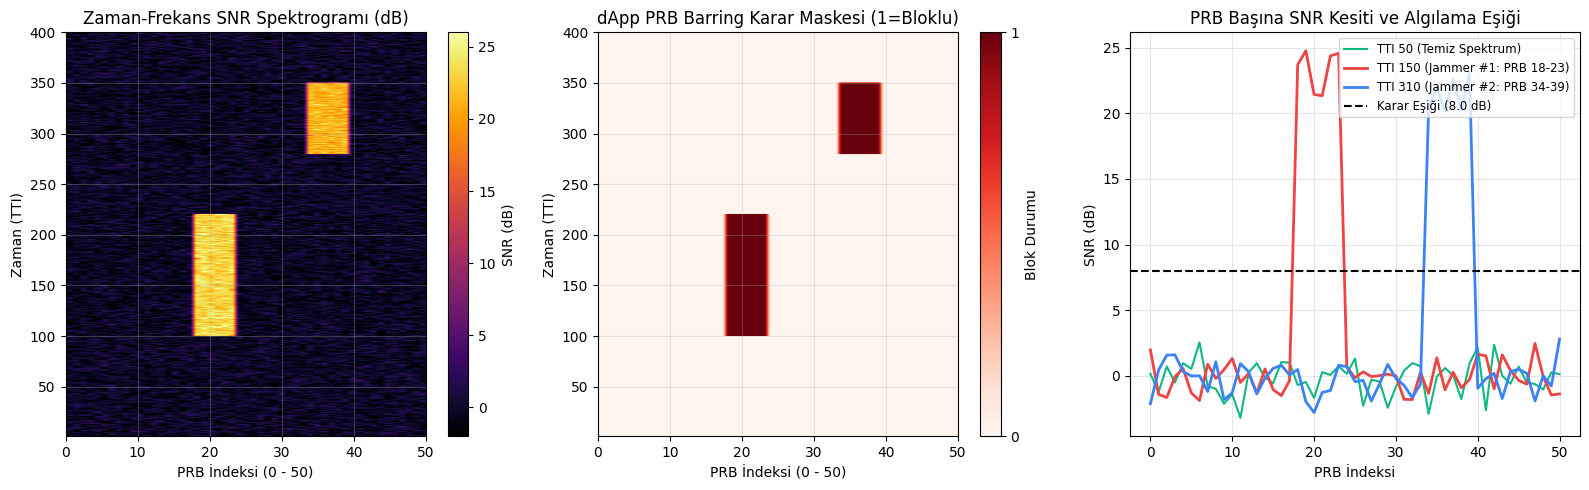

In [7]:
# Spektrogram (Waterfall), Anlık SNR Kesiti ve PRB Barring Maskesi Görselleştirmesi
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. Zaman-Frekans SNR Waterfall
im0 = axes[0].imshow(
    snr_mat, aspect="auto", origin="lower", cmap="inferno",
    extent=[0, NUM_PRBS - 1, 1, len(snr_mat)], vmin=-2, vmax=26
)
axes[0].set_title("Zaman-Frekans SNR Spektrogramı (dB)")
axes[0].set_xlabel("PRB İndeksi (0 - 50)")
axes[0].set_ylabel("Zaman (TTI)")
plt.colorbar(im0, ax=axes[0], label="SNR (dB)")

# 2. dApp Tarafından Üretilen PRB Karaliste (Barring) Karar Haritası
im1 = axes[1].imshow(
    blk_mat.astype(int), aspect="auto", origin="lower", cmap="Reds",
    extent=[0, NUM_PRBS - 1, 1, len(blk_mat)], vmin=0, vmax=1
)
axes[1].set_title("dApp PRB Barring Karar Maskesi (1=Bloklu)")
axes[1].set_xlabel("PRB İndeksi (0 - 50)")
axes[1].set_ylabel("Zaman (TTI)")
plt.colorbar(im1, ax=axes[1], ticks=[0, 1], label="Blok Durumu")

# 3. Farklı TTI Anlarında Frekans Domeni PRB SNR Kesitleri
tti_clean = 50
tti_jam1 = 150
tti_jam2 = 310
prb_axis = np.arange(NUM_PRBS)

axes[2].plot(prb_axis, snr_mat[tti_clean], label=f"TTI {tti_clean} (Temiz Spektrum)", color="#10b981", lw=1.5)
axes[2].plot(prb_axis, snr_mat[tti_jam1], label=f"TTI {tti_jam1} (Jammer #1: PRB 18-23)", color="#ef4444", lw=2)
axes[2].plot(prb_axis, snr_mat[tti_jam2], label=f"TTI {tti_jam2} (Jammer #2: PRB 34-39)", color="#3b82f6", lw=2)
axes[2].axhline(SNR_THRESHOLD_DB, color="black", linestyle="--", lw=1.5, label=f"Karar Eşiği ({SNR_THRESHOLD_DB} dB)")
axes[2].set_title("PRB Başına SNR Kesiti ve Algılama Eşiği")
axes[2].set_xlabel("PRB İndeksi")
axes[2].set_ylabel("SNR (dB)")
axes[2].legend(loc="upper right", fontsize=8.5)

plt.tight_layout()
plt.show()

---
## 4️⃣ Bölüm 4: Use Case 3 — `dApp-library` Spektrum Dedektörleri ve Özel (Custom) dApp Politikası Geliştirme

`dApp-library/src/spectrum` paketi, gerçek OAI gNB / USRP / RFSim ortamlarında kullanılan üç temel algılama mimarisi sunar:
1. **`StaticThresholdDetector`:** Belirli sayıda çerçeveyi (`window`) biriktirip ortalamasını sabit bir dB eşiği ile karşılaştırır.
2. **`AdaptiveThresholdDetector`:** Her FFT bin'i için akan medyan (`AdaptiveNoiseFloor`) ile dinamik gürültü tabanı çıkarır ve radar taramalarında PRB dalgalanmasını (flapping) önlemek için çift katmanlı **`EmbargoManager`** (tutma süresi + asimetrik IIR sönümleme) kullanır.
3. **`BaselinePolicy` (`PolicyDetector`):** `spectrum.policy.Policy` arayüzünü kullanan referans politika (`examples/hackathon_policy.py`).

### 🛠️ Yeni Bir dApp Politikası Geliştirme: `SmartGuardBandPolicy`
Gerçek 5G NR senaryolarında güçlü bir parazit (Jammer veya Radar), FFT pencereleme sızıntısı (spectral leakage) nedeniyle komşu PRB'leri de bozar. Aşağıda `spectrum.policy.Policy` sınıfından türetilen yeni bir dApp politikası geliştiriyoruz:
- **Özellik 1 (EWMA Filtreleme):** Anlık gürültü sıçramalarından (spike) etkilenmemek için PRB güçlerini üstel hareketli ortalama ile yumuşatır.
- **Özellik 2 (Guard-Band Koruması):** Çok güçlü parazit (>18 dB SNR) tespit edilen PRB bloklarının sağ ve solundaki $\pm 1$ komşu PRB'yi koruma bandı (guard-band) olarak otomatik bloklar.
- **Özellik 3 (Histerezis & Hold Time):** Kararlılığı korumak için ayarlanabilir tutma süresi uygular.

In [8]:
from __future__ import annotations
from typing import Dict, Optional, Set

class SmartGuardBandPolicy(Policy):
    """EWMA yumuşatma, dinamik medyan eşikleme ve komşu PRB koruma bandı (Guard-Band)
    içeren gelişmiş O-RAN Spektrum Koruma dApp Politikası.
    """

    def __init__(
        self,
        margin_db: float = 10.0,
        severe_margin_db: float = 18.0,
        alpha: float = 0.45,
        hold_s: float = 0.08,
        guard_prbs: int = 1,
        history_len: int = 64,
    ) -> None:
        super().__init__(history_len=history_len)
        self.margin_db = margin_db
        self.severe_margin_db = severe_margin_db
        self.alpha = alpha
        self.hold_s = hold_s
        self.guard_prbs = guard_prbs
        self._ema_power: Optional[np.ndarray] = None
        self._last_hot: Dict[int, float] = {}

    def reset(self) -> None:
        super().reset()
        self._ema_power = None
        self._last_hot.clear()

    def update(self, obs: Observation) -> Set[int]:
        level = np.where(np.isnan(obs.prb_power_db), 0.0, obs.prb_power_db)
        if self._ema_power is None:
            self._ema_power = level.copy()
        else:
            self._ema_power = self.alpha * level + (1.0 - self.alpha) * self._ema_power

        # Medyan gürültü tabanı tahmini
        floor = float(np.median(self._ema_power))
        snr = self._ema_power - floor

        # Normal ve şiddetli parazit PRB'lerini bul
        hot_prbs = set(int(p) for p in np.where(snr > self.margin_db)[0])
        severe_prbs = [int(p) for p in np.where(snr > self.severe_margin_db)[0]]

        # Şiddetli parazitlerin komşu PRB'lerini Guard-Band olarak ekle
        for p in severe_prbs:
            for g in range(1, self.guard_prbs + 1):
                if p - g >= 0:
                    hot_prbs.add(p - g)
                if p + g < obs.num_prbs:
                    hot_prbs.add(p + g)

        for p in hot_prbs:
            self._last_hot[p] = obs.t

        # Tutma süresi (hold_s) dolan PRB'leri serbest bırak
        self._last_hot = {p: t for p, t in self._last_hot.items() if (obs.t - t) <= self.hold_s}
        return set(self._last_hot)

print("✅ SmartGuardBandPolicy başarıyla tanımlandı!")

✅ SmartGuardBandPolicy başarıyla tanımlandı!


In [9]:
# 4 Dedektör / Politika Algoritmasının Zorlu RF Senaryosu Altında Karşılaştırılması
# Senaryo: 51 PRB, FFT=1024, 300 zaman adımı (dt = 5 ms -> 1.5 saniye)
# - Adım 40..120 : PRB 10..15 arasında güçlü sabit Jammer (+22 dB) + komşu PRB'lerde yan lob sızıntısı (+11 dB)
# - Adım 170..240: PRB 30..35 arasında kesikli (pulsed / radar) sinyal (her 4 adımda 2 adım aktif)

N_STEPS = 300
DT = 0.005  # 5 ms
N_PRB = 51
FFT_SIZE = compute_fft_size(N_PRB, e_sampling=False)
N_SC = N_PRB * 12

# Dedektör örneklerini oluştur
det_static = StaticThresholdDetector(threshold_db=46.0, fft_size=FFT_SIZE, window=4)
det_adaptive = AdaptiveThresholdDetector(snr_threshold_db=10.0, fft_size=FFT_SIZE, hist_depth=16, embargo_timeout_secs=0.05)
det_baseline = PolicyDetector(BaselinePolicy(margin_db=10.0, hold_s=0.05), fft_size=FFT_SIZE, num_prbs=N_PRB)
det_smart = PolicyDetector(SmartGuardBandPolicy(margin_db=9.0, severe_margin_db=17.0, hold_s=0.05, guard_prbs=1), fft_size=FFT_SIZE, num_prbs=N_PRB)

detectors = {
    "StaticThreshold (win=4)": det_static,
    "AdaptiveThreshold (med+embargo)": det_adaptive,
    "BaselinePolicy (Reference)": det_baseline,
    "SmartGuardBandPolicy (Bizim dApp)": det_smart,
}

ground_truth_prbs = np.zeros((N_STEPS, N_PRB), dtype=bool)
det_outputs = {name: np.zeros((N_STEPS, N_PRB), dtype=bool) for name in detectors}

rng = np.random.default_rng(1234)

for step in range(N_STEPS):
    t_sec = step * DT
    # Taban gürültüsü: genlik ~ 80 (20*log10(80) ≈ 38 dB)
    mag = rng.normal(80.0, 12.0, FFT_SIZE).clip(10.0, None).astype(np.float32)

    # Dalga 1: Sabit Jammer (PRB 11..14 merkez, PRB 10 ve 15 yan sızıntı)
    if 40 <= step <= 120:
        ground_truth_prbs[step, 10:16] = True
        mag[11*12 : 15*12] += rng.normal(900.0, 80.0, 4*12).astype(np.float32)  # ~60 dB (+22 dB SNR)
        mag[10*12 : 11*12] += rng.normal(160.0, 30.0, 12).astype(np.float32)    # yan lob sızıntısı
        mag[15*12 : 16*12] += rng.normal(160.0, 30.0, 12).astype(np.float32)    # yan lob sızıntısı

    # Dalga 2: Kesikli Radar / Pulsed Jammer (PRB 30..35)
    if 170 <= step <= 240:
        ground_truth_prbs[step, 30:36] = True
        if (step % 4) in (0, 1):  # %50 duty-cycle darbeli radar
            mag[30*12 : 36*12] += rng.normal(750.0, 70.0, 6*12).astype(np.float32)

    # Anlık tek-kare gürültü iğnesi (Spurious spike - yanlış alarm testi)
    if step in (25, 145, 265):
        mag[44*12 : 45*12] += 320.0

    for name, det in detectors.items():
        ready, blocked_sc, _, _ = det.update(mag, t_sec)
        if ready:
            # Alt taşıyıcı kararını PRB kararına dönüştür (herhangi bir alt taşıyıcı blokluysa PRB bloklu)
            prb_blk = blocked_sc[:N_SC].reshape(N_PRB, 12).any(axis=1)
            det_outputs[name][step] = prb_blk
        elif step > 0:
            # StaticThreshold pencere dolana kadar önceki kararı korur
            det_outputs[name][step] = det_outputs[name][step - 1]

# Performans Metriklerini (Precision, Recall, F1, False Positive Rate) Hesapla
# İlk 20 adım ısınma (warm-up) sonrası değerlendirilir
eval_gt = ground_truth_prbs[20:].ravel()
metrics_summary = {}

print(f"{'Algoritma / Politika':<34} | {'Precision':<10} | {'Recall':<10} | {'F1-Skoru':<10} | {'Yanlış Alarm (FPR)':<18}")
print("-" * 92)
for name, pred_mat in det_outputs.items():
    pred = pred_mat[20:].ravel()
    tp = int(np.sum(pred & eval_gt))
    fp = int(np.sum(pred & ~eval_gt))
    fn = int(np.sum(~pred & eval_gt))
    tn = int(np.sum(~pred & ~eval_gt))

    precision = tp / (tp + fp + 1e-9)
    recall = tp / (tp + fn + 1e-9)
    f1 = 2 * precision * recall / (precision + recall + 1e-9)
    fpr = fp / (fp + tn + 1e-9)
    metrics_summary[name] = {"precision": precision, "recall": recall, "f1": f1, "fpr": fpr}
    print(f"{name:<34} | {precision*100:>8.1f}% | {recall*100:>8.1f}% | {f1*100:>8.1f}% | {fpr*100:>16.2f}%")

Algoritma / Politika               | Precision  | Recall     | F1-Skoru   | Yanlış Alarm (FPR)
--------------------------------------------------------------------------------------------
StaticThreshold (win=4)            |     93.1% |     94.7% |     93.9% |             0.48%
AdaptiveThreshold (med+embargo)    |     85.3% |     70.7% |     77.3% |             0.83%
BaselinePolicy (Reference)         |     86.0% |     89.0% |     87.5% |             0.99%
SmartGuardBandPolicy (Bizim dApp)  |     88.9% |     98.0% |     93.2% |             0.84%


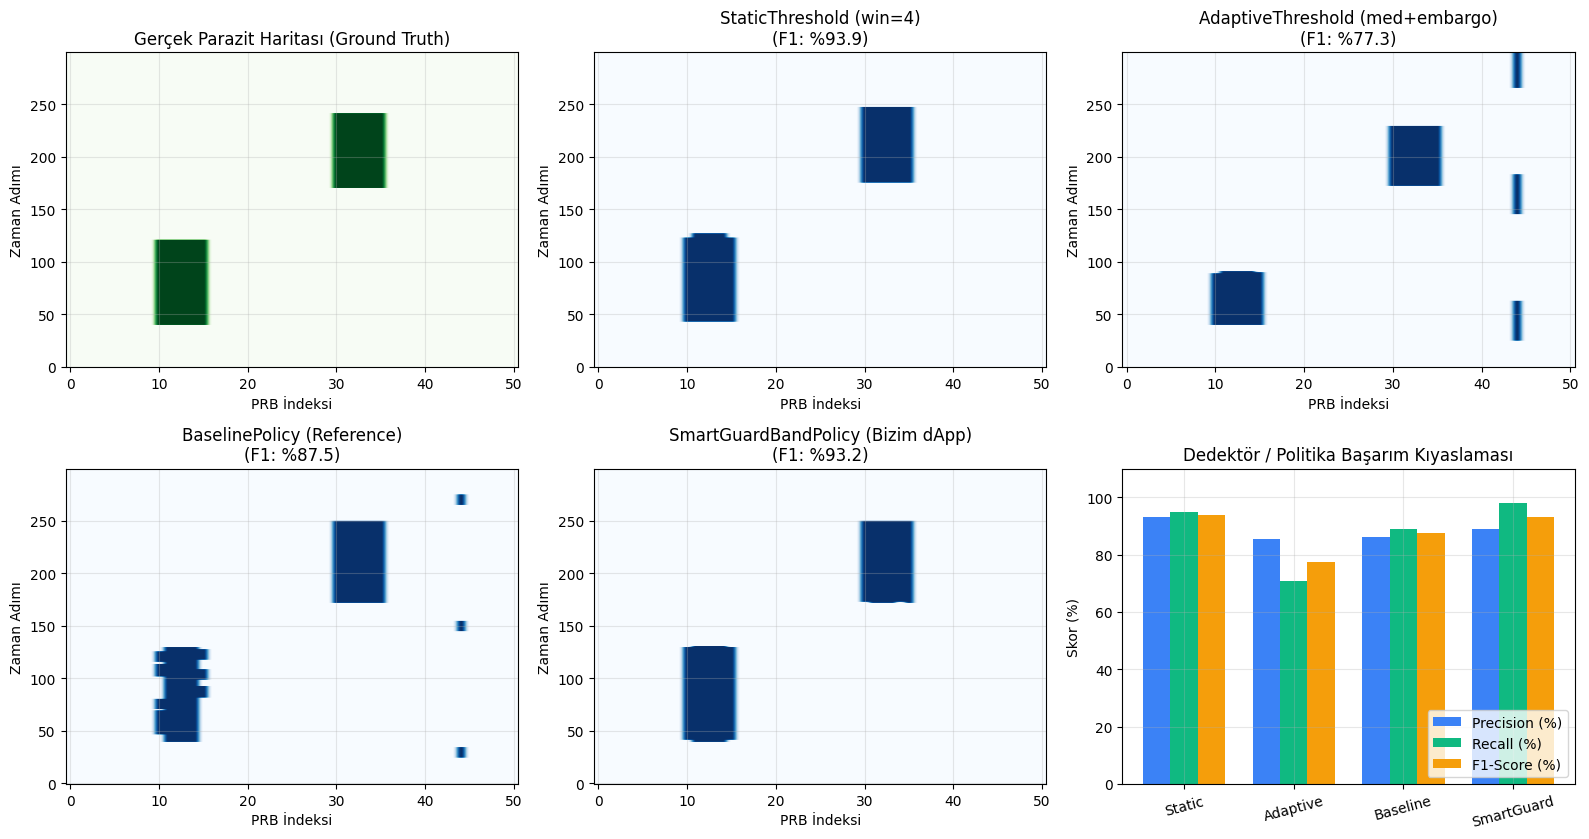

In [10]:
# Dedektör Karar Maskelerinin ve Performans Metriklerinin Görsel Karşılaştırması
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))

# Üst satır: Ground Truth + İlk 2 Dedektör
axes[0, 0].imshow(ground_truth_prbs.astype(int), aspect="auto", origin="lower", cmap="Greens")
axes[0, 0].set_title("Gerçek Parazit Haritası (Ground Truth)")
axes[0, 0].set_xlabel("PRB İndeksi")
axes[0, 0].set_ylabel("Zaman Adımı")

names = list(det_outputs.keys())
positions = [(0, 1), (0, 2), (1, 0), (1, 1)]
for (r, c), name in zip(positions, names):
    axes[r, c].imshow(det_outputs[name].astype(int), aspect="auto", origin="lower", cmap="Blues")
    f1_val = metrics_summary[name]["f1"] * 100
    axes[r, c].set_title(f"{name}\n(F1: %{f1_val:.1f})")
    axes[r, c].set_xlabel("PRB İndeksi")
    axes[r, c].set_ylabel("Zaman Adımı")

# Sağ alt: Bar grafik ile Precision / Recall / F1 karşılaştırması
ax_bar = axes[1, 2]
x = np.arange(len(names))
w = 0.25
ax_bar.bar(x - w, [metrics_summary[n]["precision"]*100 for n in names], w, label="Precision (%)", color="#3b82f6")
ax_bar.bar(x,     [metrics_summary[n]["recall"]*100 for n in names],    w, label="Recall (%)",    color="#10b981")
ax_bar.bar(x + w, [metrics_summary[n]["f1"]*100 for n in names],        w, label="F1-Score (%)",  color="#f59e0b")
ax_bar.set_xticks(x)
ax_bar.set_xticklabels(["Static", "Adaptive", "Baseline", "SmartGuard"], rotation=15)
ax_bar.set_ylim(0, 110)
ax_bar.set_ylabel("Skor (%)")
ax_bar.set_title("Dedektör / Politika Başarım Kıyaslaması")
ax_bar.legend(loc="lower right")

plt.tight_layout()
plt.show()

---
## 5️⃣ Bölüm 5: Birim ve Entegrasyon Test Koşumu (`pytest` & `libe3`)

Son adımda hem `libe3` SWIG smoke testini hem de `dApp-library/tests` altındaki birim ve entegrasyon testlerini doğrudan Notebook içerisinden çalıştırarak tüm alt sistemlerin doğruluğunu teyit ediyoruz.

In [11]:
# 1. libe3 SWIG Smoke Testi
swig_smoke = subprocess.run(
    [sys.executable, "libe3/tests/test_swig_smoke.py"],
    capture_output=True, text=True
)
print("=== [1] libe3 SWIG Smoke Testi ===")
print(swig_smoke.stdout.strip())

# 2. dApp-library Pytest Test Paketi Koşumu
pytest_Target_Tests = [
    "dApp-library/tests/test_policy.py",
    "dApp-library/tests/test_detector_configure.py",
    "dApp-library/tests/test_detector_granularity_pipeline.py",
    "dApp-library/tests/test_ru_profiles.py",
    "dApp-library/tests/test_protobuf_sm.py",
    "dApp-library/tests/test_indication_dispatch.py",
    "dApp-library/tests/test_libe3_agent.py",
]

pytest_run = subprocess.run(
    [sys.executable, "-m", "pytest", "-v", "-o", "addopts="] + pytest_Target_Tests,
    capture_output=True, text=True
)
print("\n=== [2] dApp-library Birim & Entegrasyon Test Sonuçları ===")
print(pytest_run.stdout[-2500:] if len(pytest_run.stdout) > 2500 else pytest_run.stdout)
if pytest_run.returncode != 0:
    print("STDERR:", pytest_run.stderr)

=== [1] libe3 SWIG Smoke Testi ===
OK: libe3py imports, E3Config/E3Role/E3Agent constructible, dApp surface present, bytes typemaps + GIL release verified



=== [2] dApp-library Birim & Entegrasyon Test Sonuçları ===
one_means_not_passed PASSED [ 57%]
dApp-library/tests/test_ru_profiles.py::test_zero_threshold_is_an_explicit_value PASSED [ 59%]
dApp-library/tests/test_ru_profiles.py::test_max_samples_follows_overridden_geometry PASSED [ 61%]
dApp-library/tests/test_ru_profiles.py::test_uncalibrated_profile_falls_back_to_generic_defaults PASSED [ 63%]
dApp-library/tests/test_ru_profiles.py::test_every_profile_resolves PASSED [ 65%]
dApp-library/tests/test_ru_profiles.py::test_usrp_family_uses_small_beta PASSED [ 68%]
dApp-library/tests/test_protobuf_sm.py::test_spectrum_prb_blacklist_control_roundtrip PASSED [ 70%]
dApp-library/tests/test_protobuf_sm.py::test_spectrum_empty_prb_blacklist_roundtrip PASSED [ 72%]
dApp-library/tests/test_protobuf_sm.py::test_spectrum_xapp_config_control_decode PASSED [ 74%]
dApp-library/tests/test_protobuf_sm.py::test_spectrum_sensing_indication_decode PASSED [ 76%]
dApp-library/tests/test_protobuf_sm.py::tes